# Lab 2: Зниження розмірності, кластеризація та класифікація текстових даних

Камінський Валентин, ФБ-61мн



In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, silhouette_score, adjusted_rand_score

from sklearn import set_config
set_config(display="text")

## Get the Data

Передобробка така сама, як у Lab 1.

In [2]:
df = pd.read_csv('CTU-IoT-Malware-Capture-1-1conn.log.labeled.csv', sep='|', na_values=['-'], low_memory=False)
df.shape

(1008748, 23)

In [3]:
df = df.drop(['ts', 'uid', 'id.orig_h', 'id.resp_h', 'local_orig', 'local_resp',
              'tunnel_parents', 'detailed-label'], axis=1)

# '-' у duration/bytes означає, що з'єднання не встановилось -> 0
for col in ['duration', 'orig_bytes', 'resp_bytes']:
    df[col] = df[col].fillna(0)
for col in ['service', 'history']:
    df[col] = df[col].fillna('none')

for col in ['proto', 'service', 'conn_state', 'history']:
    df[col] = LabelEncoder().fit_transform(df[col])

df['label'] = (df['label'] == 'Malicious').astype(int)

In [4]:
X = df.drop(['label'], axis=1)
y = df['label']
print(X.shape)
print(y.value_counts())

(1008748, 14)
label
1    539473
0    469275
Name: count, dtype: int64


## Частина 1. Зниження розмірності

### Train Test Split

Для порівняння "до" і "після" PCA беремо kNN (k=3, як у Lab 1). kNN рахує відстані між точками, тому для нього кількість ознак найбільше впливає на час.  
На всіх 1 млн рядків predict kNN займає приблизно 5 хв, тому беру підвибірку 100 тис. рядків.

In [5]:
X_small, _, y_small, _ = train_test_split(X, y, train_size=100000, random_state=42, stratify=y)
X_train, X_test, y_train, y_test = train_test_split(X_small, y_small, test_size=0.2, random_state=42, stratify=y_small)

scaler = StandardScaler()
scaler.fit(X_train)
scaled_X_train = scaler.transform(X_train)
scaled_X_test = scaler.transform(X_test)
print(scaled_X_train.shape, scaled_X_test.shape)

(80000, 14) (20000, 14)


### KNN without PCA

In [6]:
knn = KNeighborsClassifier(n_neighbors=3)

t0 = time.perf_counter()
knn.fit(scaled_X_train, y_train)
t1 = time.perf_counter()
pred = knn.predict(scaled_X_test)
t2 = time.perf_counter()

acc_no_pca = accuracy_score(y_test, pred)
fit_no_pca, pred_no_pca = t1 - t0, t2 - t1
print('accuracy:', acc_no_pca)
print('fit time:', round(fit_no_pca, 3), 's')
print('predict time:', round(pred_no_pca, 3), 's')

accuracy: 0.99575
fit time: 0.152 s
predict time: 3.446 s


In [7]:
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))

[[ 9221    83]
 [    2 10694]]
              precision    recall  f1-score   support

           0       1.00      0.99      1.00      9304
           1       0.99      1.00      1.00     10696

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000



### PCA

Спочатку дивимось, скільки дисперсії пояснює кожна компонента.

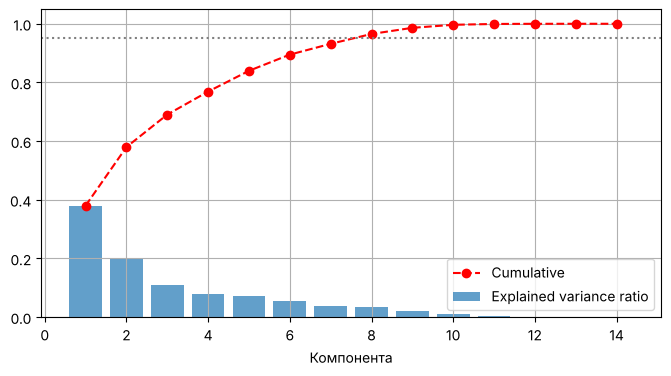

In [8]:
pca_full = PCA()
pca_full.fit(scaled_X_train)

evr = pca_full.explained_variance_ratio_
cum_evr = np.cumsum(evr)

plt.figure(figsize=(8, 4))
plt.bar(range(1, len(evr) + 1), evr, alpha=0.7, label='Explained variance ratio')
plt.plot(range(1, len(evr) + 1), cum_evr, marker='o', color='red', linestyle='--', label='Cumulative')
plt.axhline(0.95, color='gray', linestyle=':')
plt.xlabel('Компонента')
plt.legend()
plt.grid()
plt.show()

In [9]:
np.round(cum_evr, 3)

array([0.38 , 0.58 , 0.691, 0.769, 0.84 , 0.895, 0.932, 0.965, 0.986,
       0.997, 0.999, 1.   , 1.   , 1.   ])

Ознаки сильно корелюють між собою (наприклад, `orig_pkts` і `orig_ip_bytes`), тому перші компоненти пояснюють більшу частину дисперсії. Беремо стільки компонент, щоб зберегти 95% дисперсії.

In [10]:
pca = PCA(n_components=0.95)
pca.fit(scaled_X_train)
pca_X_train = pca.transform(scaled_X_train)
pca_X_test = pca.transform(scaled_X_test)

print('ознак було:', scaled_X_train.shape[1])
print('компонент стало:', pca.n_components_)

ознак було: 14
компонент стало: 8


### KNN with PCA

In [11]:
knn_pca = KNeighborsClassifier(n_neighbors=3)

t0 = time.perf_counter()
knn_pca.fit(pca_X_train, y_train)
t1 = time.perf_counter()
pred_pca = knn_pca.predict(pca_X_test)
t2 = time.perf_counter()

acc_pca = accuracy_score(y_test, pred_pca)
fit_pca, pred_time_pca = t1 - t0, t2 - t1
print('accuracy:', acc_pca)
print('fit time:', round(fit_pca, 3), 's')
print('predict time:', round(pred_time_pca, 3), 's')

accuracy: 0.9955
fit time: 0.08 s
predict time: 0.104 s


In [12]:
print(confusion_matrix(y_test, pred_pca))
print(classification_report(y_test, pred_pca))

[[ 9216    88]
 [    2 10694]]
              precision    recall  f1-score   support

           0       1.00      0.99      1.00      9304
           1       0.99      1.00      1.00     10696

    accuracy                           1.00     20000
   macro avg       1.00      1.00      1.00     20000
weighted avg       1.00      1.00      1.00     20000



In [13]:
pd.DataFrame({
    'ознак': [scaled_X_train.shape[1], pca.n_components_],
    'accuracy': [acc_no_pca, acc_pca],
    'fit, s': [fit_no_pca, fit_pca],
    'predict, s': [pred_no_pca, pred_time_pca]
}, index=['без PCA', 'з PCA (95%)'])

,ознак,accuracy,"fit, s","predict, s"
без PCA,14,0.99575,0.152439,3.445607
з PCA (95%),8,0.99550,0.079645,0.103737


Для цікавості: що буде, якщо залишити зовсім мало компонент:

In [14]:
for n in [2, 3, 5]:
    p = PCA(n_components=n).fit(scaled_X_train)
    m = KNeighborsClassifier(n_neighbors=3).fit(p.transform(scaled_X_train), y_train)
    print(n, 'компоненти -> accuracy', accuracy_score(y_test, m.predict(p.transform(scaled_X_test))))

2 компоненти -> accuracy 0.9946


3 компоненти -> accuracy 0.9953


5 компоненти -> accuracy 0.99525


Висновки по PCA:
PCA залишив 8 компонент замість 14 ознак (менше майже вдвічі) і зберіг 95% дисперсії.
Якість майже не змінилась: accuracy 0.99575 без PCA і 0.9955 з PCA - різниця 5 помилок на 20 тис. Навіть з 2 компонентами точність 0.9946 - класи в цих даних розділяються дуже легко (це було видно ще в Lab 1).
Час fit у kNN і так майже нульовий (він тільки запам'ятовує дані), а от predict став швидшим у десятки разів (див. таблицю). Причина не тільки в тому, що вимірів менше: kNN шукає сусідів через дерево (KD-tree), а воно добре працює в малій розмірності і погано у великій.

### t-SNE

t-SNE рахує відстані між усіма парами точок, на 1 млн рядків це нереально, тому беру випадкові 5000 рядків. Для порівняння поруч - PCA на тих самих точках.

In [15]:
X_vis, _, y_vis, _ = train_test_split(X, y, train_size=5000, random_state=42, stratify=y)
X_vis_scaled = StandardScaler().fit_transform(X_vis)

In [16]:
tsne = TSNE(n_components=2, random_state=42)
tsne_result = tsne.fit_transform(X_vis_scaled)

pca_result = PCA(n_components=2).fit_transform(X_vis_scaled)

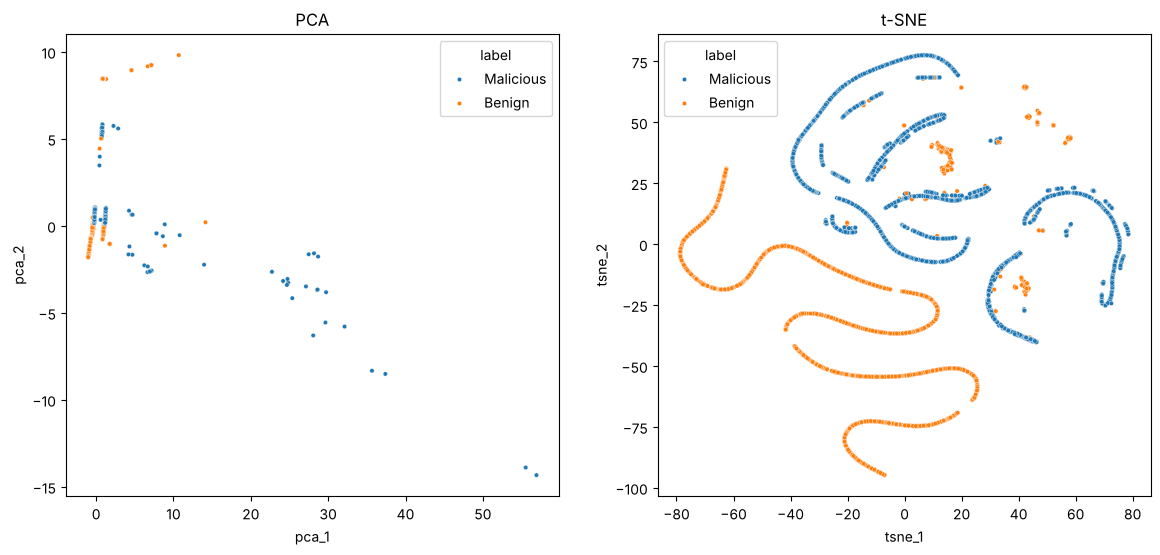

In [17]:
tsne_df = pd.DataFrame({'tsne_1': tsne_result[:, 0], 'tsne_2': tsne_result[:, 1], 'label': y_vis.map({0: 'Benign', 1: 'Malicious'}).values})
pca_df = pd.DataFrame({'pca_1': pca_result[:, 0], 'pca_2': pca_result[:, 1], 'label': y_vis.map({0: 'Benign', 1: 'Malicious'}).values})

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.scatterplot(x='pca_1', y='pca_2', hue='label', data=pca_df, ax=axes[0], s=10)
axes[0].set_title('PCA')
sns.scatterplot(x='tsne_1', y='tsne_2', hue='label', data=tsne_df, ax=axes[1], s=10)
axes[1].set_title('t-SNE')
plt.show()

- На PCA більшість точок злиплась у кількох місцях біля нуля - багато з'єднань однакові (у Lab 1 було 64% дублікатів), і класи там накладаються. PCA - лінійна проекція, вона зберігає загальну дисперсію, а не близьких сусідів, тому довгий "хвіст" праворуч - це рідкісні довгі шкідливі сесії, які дають найбільшу дисперсію.
- На t-SNE класи розділились значно краще: легітимний трафік (Benign) зібрався в окремі довгі "нитки" зліва внизу, шкідливий - у групи справа і зверху. t-SNE зберігає локальну структуру (хто чий сусід), тому схожі з'єднання опиняються поруч.
- Форма "ниток" - це ланцюжки з'єднань, які відрізняються майже тільки портом джерела (у Mirai він випадковий), тому сусідні точки вишиковуються в лінію.
- Кілька маленьких помаранчевих острівців серед синіх - це легітимні TCP-з'єднання, схожі на шкідливі. Саме на них помиляються класифікатори.
- Координати t-SNE не мають фізичного змісту і відстані між далекими групами нічого не означають - важливо тільки, хто з ким поруч.

## Частина 2. Кластеризація K-Means

Мітки класів (`label`) під час кластеризації не використовуються - тільки X. Дані масштабуємо, бо K-Means працює з відстанями.

In [18]:
X_scaled = StandardScaler().fit_transform(X)
X_scaled.shape

(1008748, 14)

### Elbow plot

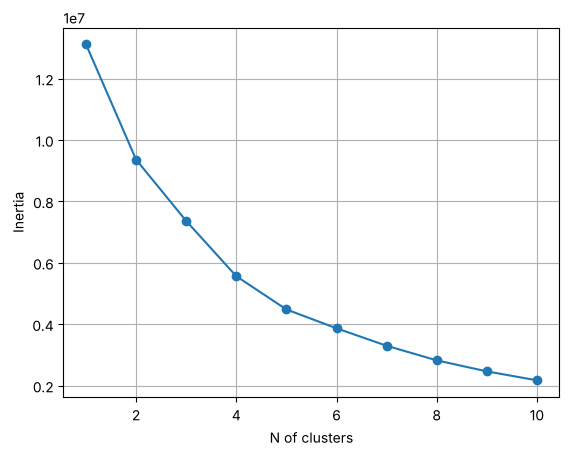

In [19]:
Error = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    Error.append(kmeans.inertia_)

plt.plot(range(1, 11), Error, marker='o')
plt.xlabel('N of clusters')
plt.ylabel('Inertia')
plt.grid()
plt.show()

Чіткого "ліктя" немає - крива плавна. Найсильніше inertia падає до k=4, після k=5 спад вже невеликий. Тобто доцільно k = 4-5.

### Silhouette score

silhouette_score рахує відстані між усіма парами точок, тому рахую його на випадковій вибірці 10000 точок (`sample_size`).

In [20]:
for i in range(2, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans_labels = kmeans.fit_predict(X_scaled)
    silhouette_avg = silhouette_score(X_scaled, kmeans_labels, sample_size=10000, random_state=42)
    print("For n_clusters =", i, " silhouette average:", round(silhouette_avg, 3))

For n_clusters = 2  silhouette average: 0.905


For n_clusters = 3  silhouette average: 0.439


For n_clusters = 4  silhouette average: 0.49


For n_clusters = 5  silhouette average: 0.51


For n_clusters = 6  silhouette average: 0.541


For n_clusters = 7  silhouette average: 0.543


For n_clusters = 8  silhouette average: 0.543


For n_clusters = 9  silhouette average: 0.567


For n_clusters = 10  silhouette average: 0.566


Найвищий silhouette при k=2 (0.905), але це пастка - подивимось, які кластери він дає:

In [21]:
kmeans2 = KMeans(n_clusters=2, random_state=42, n_init=10)
labels2 = kmeans2.fit_predict(X_scaled)
pd.crosstab(labels2, y, rownames=['cluster'], colnames=['label'])

label,0,1
cluster,,
0,469156,535669
1,119,3804


При k=2 K-Means просто відділяє маленьку групу з приблизно 3900 точок від усіх інших. Ці точки дуже далеко від решти (довгі сесії з великою кількістю пакетів), тому silhouette високий - кластери добре розділені. Але з класами такий поділ не має нічого спільного: в обох кластерах є і Benign, і Malicious.

Тому k вибираю за elbow - k=4, де silhouette теж нормальний (0.49).

### K-Means, k = 4

In [22]:
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
pd.Series(clusters).value_counts().sort_index()

0    416232
1    566963
2      3824
3     21729
Name: count, dtype: int64

### Порівняння кластерів з класами

In [23]:
pd.crosstab(clusters, y.map({0: 'Benign', 1: 'Malicious'}), rownames=['cluster'], colnames=['label'])

label,Benign,Malicious
cluster,,
0,416198,34
1,35194,531769
2,76,3748
3,17807,3922


In [24]:
print('ARI k=2:', adjusted_rand_score(y, labels2))
print('ARI k=4:', adjusted_rand_score(y, clusters))

ARI k=2: -0.0008927032985178956
ARI k=4: 0.8206458296381294


ARI (adjusted rand index) показує, наскільки розбиття на кластери збігається з реальними класами: 1 - повний збіг, 0 - як випадкове розбиття.

In [25]:
# середні значення ознак у кожному кластері - щоб зрозуміти, що це за кластери
df_cl = df.copy()
df_cl['cluster'] = clusters
df_cl.groupby('cluster')[['proto', 'id.resp_p', 'duration', 'orig_pkts', 'orig_ip_bytes', 'resp_pkts', 'label']].mean().round(2)

,proto,id.resp_p,duration,orig_pkts,orig_ip_bytes,resp_pkts,label
cluster,,,,,,,
0,1.98,32519.69,0.00,1.00,41.12,0.02,0.00
1,1.00,4714.45,1.06,1.72,102.69,0.05,0.94
2,0.99,433.11,14.56,24.64,1245.97,27.42,0.98
3,0.20,1298.77,1.04,1.18,80.59,0.20,0.18


`proto` після LabelEncoder: 0 = icmp, 1 = tcp, 2 = udp.

- Кластер 0 - UDP (proto=2), 1 пакет, порти по всьому діапазону. Це майже чистий легітимний трафік.
- Кластер 1 - TCP, низькі порти, 1-3 пакети без відповіді. Це SYN-сканування Mirai (94% Malicious).
- Кластер 2 - TCP, довгі сесії (в середньому 15 с і 25 пакетів, є відповіді). Тобто з'єднання, які встановились - 98% Malicious, ймовірно успішні підключення бота до Telnet. Саме цей кластер K-Means відділяв при k=2.
- Кластер 3 - переважно ICMP (середнє proto 0.2), 82% Benign.

### Visualization (PCA 2D)

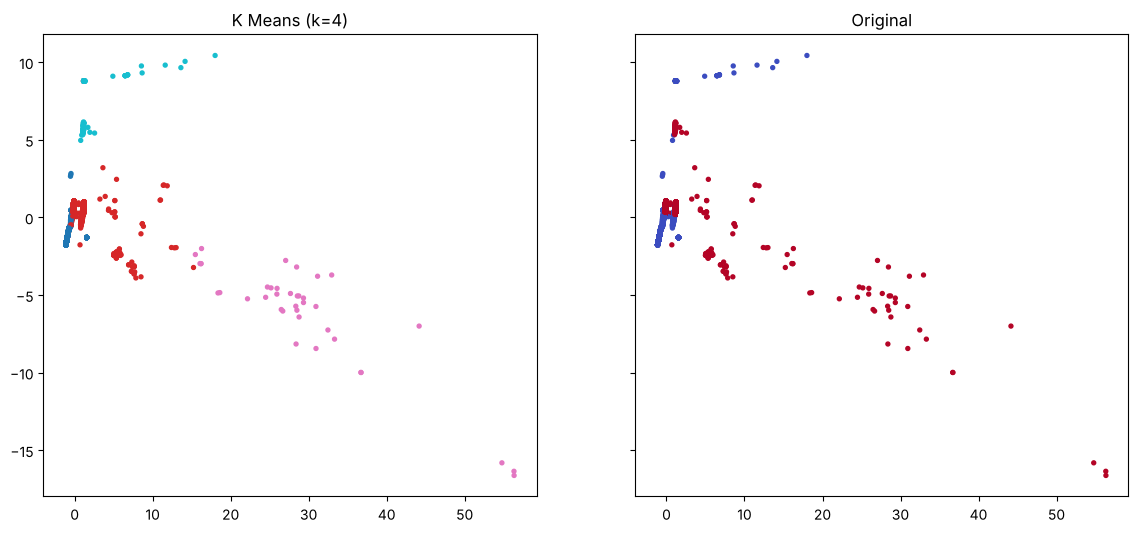

In [26]:
idx = np.random.RandomState(42).choice(len(X_scaled), 10000, replace=False)
pca_2d = PCA(n_components=2).fit_transform(X_scaled[idx])

f, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
ax1.set_title('K Means (k=4)')
ax1.scatter(pca_2d[:, 0], pca_2d[:, 1], c=clusters[idx], cmap='tab10', s=8)
ax2.set_title('Original')
ax2.scatter(pca_2d[:, 0], pca_2d[:, 1], c=y.values[idx], cmap='coolwarm', s=8)
plt.show()

Висновок: кластерна структура частково відповідає класам. K-Means не знає міток, він групує з'єднання за схожістю: протокол, кількість пакетів, тривалість. Через те що легітимний трафік тут здебільшого UDP/ICMP, а шкідливий - TCP-сканування, кластери за типом трафіку майже збігаються з класами (ARI = 0.82 при k=4).

Кластер і клас - не одне й те саме:
K-Means розділив шкідливий трафік на два кластери (сканування і встановлені сесії) - це різна поведінка, хоча клас один.
35 тис. легітимних TCP-з'єднань потрапили в кластер сканування, бо за ознаками вони схожі.
При k=2 (найкращий silhouette) кластеризація з класами взагалі не збігається (ARI майже 0) - "найкраще" розбиття за геометрією не обов'язково найкраще за змістом.

## Частина 3. Класифікація текстів

Датасет: Phishing Email Detection - приблизно 18.6 тис. листів з мітками `Safe Email` і `Phishing Email`.  
https://www.kaggle.com/datasets/subhajournal/phishingemails

In [27]:
import re
import string
from collections import Counter
from wordcloud import WordCloud
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

### Get the Data

In [28]:
emails = pd.read_csv('Phishing_Email.csv')
emails.shape

(18650, 3)

In [29]:
emails.sample(5, random_state=42)

,Unnamed: 0,Email Text,Email Type
14469,14470,"Once upon a time, Harri wrote :> Title page ha...",Safe Email
3014,3014,new books : generative studies we would like t...,Safe Email
16941,16942,new book : japanese linguistics japanese lingu...,Safe Email
14344,14345,renewal notice for your domain name ( s ) dear...,Safe Email
8097,8098,hot stock tip your broker won ' t share now th...,Phishing Email


In [30]:
Counter(emails['Email Type'])

Counter({'Safe Email': 11322, 'Phishing Email': 7328})

In [31]:
emails.isnull().sum()

Unnamed: 0     0
Email Text    16
Email Type     0
dtype: int64

In [32]:
print('порожні:', (emails['Email Text'].str.strip() == 'empty').sum())
print('дублікати:', emails['Email Text'].duplicated().sum())
emails['Email Text'].str.len().describe()

порожні: 533
дублікати: 1112


count    1.863400e+04
mean     2.755654e+03
std      1.248677e+05
min      1.000000e+00
25%      4.040000e+02
50%      8.815000e+02
75%      1.880000e+03
max      1.703669e+07
Name: Email Text, dtype: float64

Фільтруємо:
16 листів без тексту (NaN) і 533 листи, де замість тексту стоїть слово `empty`.
1112 дублікатів - якщо їх залишити, однакові листи потраплять і в train, і в test.
Один "лист" довжиною 17 млн символів. Подивимось на нього:

In [33]:
big = emails['Email Text'].str.len().idxmax()
print(emails.loc[big, 'Email Type'])
print(emails.loc[big, 'Email Text'][:300])

Safe Email
0,"Subject: great part-time or summer job ! * * * * * * * * * * * * * * * we have display boxes with credit applications that we need to place in the small owner-operated stores in your area . here is what you do : 1 . introduce yourself to the store owner or manager . 2 . use our 90 % effective scr


Склеєний шматок іншого датасету (починається з `0,"Subject: ...` і всередині спам), хоча мітка стоїть Safe. Видаляємо.

In [34]:
emails = emails.dropna(subset=['Email Text'])
emails = emails[emails['Email Text'].str.strip() != 'empty']
emails = emails.drop_duplicates(subset=['Email Text'])
emails = emails[emails['Email Text'].str.len() < 1000000]

emails['label'] = (emails['Email Type'] == 'Phishing Email').astype(int)
print(emails.shape)
Counter(emails['Email Type'])

(17535, 4)


Counter({'Safe Email': 10978, 'Phishing Email': 6557})

Класи трохи незбалансовані (приблизно 63% / 37%), але не критично.

### Text cleaning

Залишаємо тільки англійські літери: прибираємо посилання, email-адреси, цифри, пунктуацію і зламані символи кодування. Потім видаляємо стоп-слова (список зі sklearn) і слова з однієї літери.

In [35]:
stop_words = set(ENGLISH_STOP_WORDS)

def clean_text(text):
    text = text.lower()
    text = re.sub(r"https*\S+", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)   # цифри, пунктуація, інші символи
    words = [w for w in text.split() if w not in stop_words and len(w) > 1]
    return ' '.join(words)

In [36]:
# приклад: типовий фішинговий лист "від PayPal"
print(emails.loc[8429, 'Email Text'][:400])
print()
print(clean_text(emails.loc[8429, 'Email Text'])[:400])

urgent security notification ! dear valuedpaypalmember : we recently noticed one or more attempts to log in to your paypal account from a foreign ip address . if you recently accessed your account while traveling in rusia , the unusual log in attempts may have been initiated by you . however , if you did not initiate the logins , please visit paypal as soon as possible to verify your identity : ve

urgent security notification dear valuedpaypalmember recently noticed attempts log paypal account foreign ip address recently accessed account traveling rusia unusual log attempts initiated did initiate logins visit paypal soon possible verify identity verify identity security measure ensure person access account thanks patience work protect account security sincerely paypal automatic mail sent us


In [37]:
emails['clean'] = emails['Email Text'].apply(clean_text)

### WordCloud

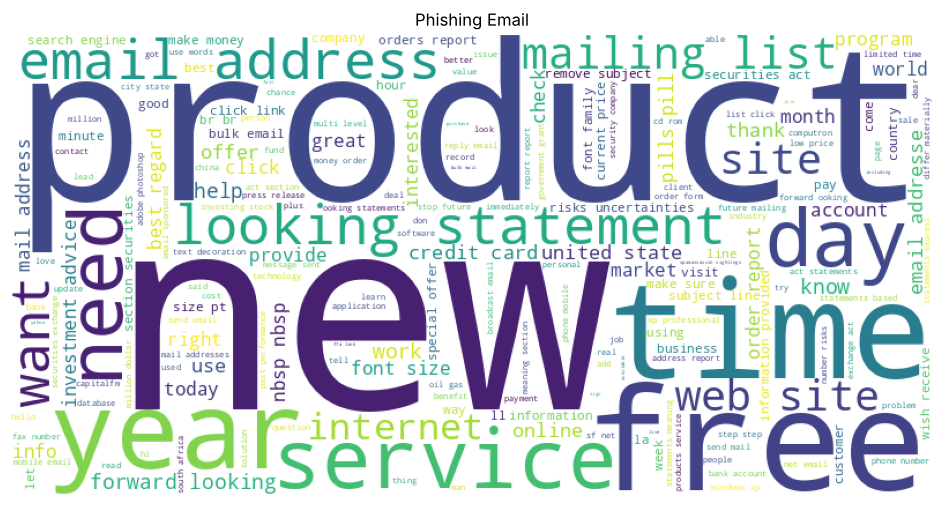

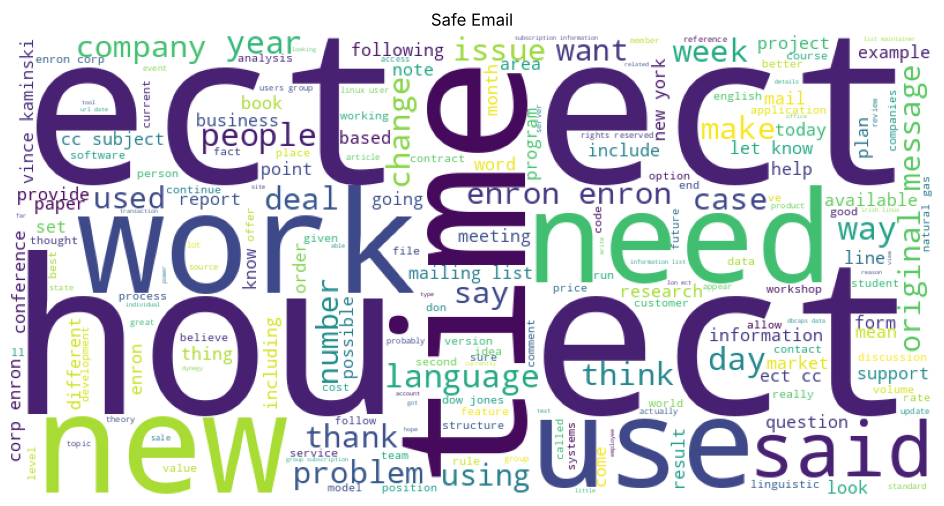

In [38]:
def visualize(label):
    text = ' '.join(emails[emails['Email Type'] == label]['clean'])
    wordcloud = WordCloud(width=800, height=400, background_color="white", random_state=42).generate(text)
    plt.figure(figsize=(12, 6))
    plt.imshow(wordcloud)
    plt.axis('off')
    plt.title(label)
    plt.show()

visualize('Phishing Email')
visualize('Safe Email')

In [39]:
for label in ['Phishing Email', 'Safe Email']:
    words = ' '.join(emails[emails['Email Type'] == label]['clean']).split()
    print(label, Counter(words).most_common(15))
    print()

Phishing Email [('email', 5066), ('free', 4243), ('com', 4152), ('mail', 3766), ('money', 3757), ('company', 3722), ('information', 3683), ('business', 3439), ('time', 3180), ('report', 3055), ('http', 3006), ('new', 2923), ('click', 2831), ('just', 2671), ('make', 2622)]



Safe Email [('enron', 17840), ('ect', 10900), ('new', 6208), ('university', 6045), ('language', 5910), ('com', 5730), ('hou', 5218), ('information', 5178), ('subject', 4674), ('list', 4596), ('said', 4491), ('time', 4379), ('mail', 4320), ('like', 4273), ('company', 4072)]



Що видно на WordCloud:
- Phishing: free, product, service, credit card, click link, email address, web site, offer. Типова лексика спаму і фішингу: щось пропонують безкоштовно, просять перейти за посиланням або залишити дані. "looking statement" - це з фрази "forward-looking statements", яку пишуть у спамі з "гарячими" акціями. nbsp і font size - залишки HTML-верстки, у звичайних листах її майже немає.
- Safe: найбільші слова ect і hou - це не слова, а частини внутрішніх адрес компанії Enron (наприклад john/hou/ect). Також enron, vince kaminski, deal, language, linguistic, conference. Безпечні листи в датасеті взяті з двох джерел: робоча пошта Enron і розсилка лінгвістів.

Тобто частина слів відрізняє не "фішинг від нормального листа", а джерело, з якого взяли листи.

### Train Test Split

In [40]:
X_train, X_test, y_train, y_test = train_test_split(emails['clean'], emails['label'], test_size=0.2, random_state=42, stratify=emails['label'])
print(X_train.shape, X_test.shape)

(14028,) (3507,)


### Vectorization (TF-IDF)

min_df=5 - слово має бути хоча б у 5 листах (прибирає опечатки і рідкісне сміття), max_df=0.9 - прибираємо слова, які є майже в усіх листах.

In [41]:
tfidf_vectorizer = TfidfVectorizer(min_df=5, max_df=0.9)
tfidf_train = tfidf_vectorizer.fit_transform(X_train)
tfidf_test = tfidf_vectorizer.transform(X_test)
print(tfidf_train.shape)

(14028, 24648)


### Model: Naive Bayes

In [42]:
nb_clf = MultinomialNB(alpha=0.1)
nb_clf.fit(tfidf_train, y_train)
nb_pred = nb_clf.predict(tfidf_test)

print(confusion_matrix(y_test, nb_pred))
print(classification_report(y_test, nb_pred, target_names=['Safe', 'Phishing'], digits=3))

[[2169   27]
 [  60 1251]]
              precision    recall  f1-score   support

        Safe      0.973     0.988     0.980      2196
    Phishing      0.979     0.954     0.966      1311

    accuracy                          0.975      3507
   macro avg      0.976     0.971     0.973      3507
weighted avg      0.975     0.975     0.975      3507



### Model: Logistic Regression

In [43]:
lr_clf = LogisticRegression(max_iter=1000)
lr_clf.fit(tfidf_train, y_train)
lr_pred = lr_clf.predict(tfidf_test)

print(confusion_matrix(y_test, lr_pred))
print(classification_report(y_test, lr_pred, target_names=['Safe', 'Phishing'], digits=3))

[[2173   23]
 [  67 1244]]
              precision    recall  f1-score   support

        Safe      0.970     0.990     0.980      2196
    Phishing      0.982     0.949     0.965      1311

    accuracy                          0.974      3507
   macro avg      0.976     0.969     0.972      3507
weighted avg      0.974     0.974     0.974      3507



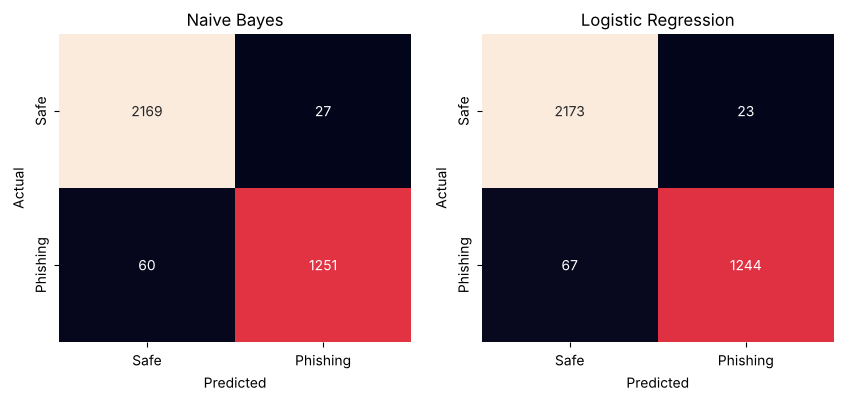

In [44]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name, p in zip(axes, ['Naive Bayes', 'Logistic Regression'], [nb_pred, lr_pred]):
    sns.heatmap(confusion_matrix(y_test, p), annot=True, fmt='d', ax=ax, cbar=False,
                xticklabels=['Safe', 'Phishing'], yticklabels=['Safe', 'Phishing'])
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.show()

Обидві моделі дають accuracy приблизно 0.975, Naive Bayes трохи кращий.

Для захисту пошти важливіший recall для Phishing: пропущений фішинговий лист (false negative) небезпечніший, ніж нормальний лист у спамі (false positive). У Naive Bayes recall 0.954 - пропущено 60 фішингових листів з 1311, у Logistic Regression 0.949 (67 пропущено). Зате LR рідше помилково блокує нормальні листи (23 проти 27).

### Найважливіші слова для моделі

У логістичної регресії кожне слово має коефіцієнт: додатний - тягне до Phishing, від'ємний - до Safe.

In [45]:
words = np.array(tfidf_vectorizer.get_feature_names_out())
coef = lr_clf.coef_[0]
print('Phishing:', list(words[np.argsort(coef)[-20:]][::-1]))
print()
print('Safe:', list(words[np.argsort(coef)[:20]]))

Phishing: ['click', 'http', 'money', 'free', 'remove', 'email', 'save', 'life', 'online', 'offer', 'software', 'reply', 'company', 'viagra', 'quality', 'hello', 'removed', 'best', 'info', 'low']

Safe: ['enron', 'url', 'wrote', 'thanks', 'date', 'language', 'university', 'vince', 'attached', 'linguistics', 'edu', 'pm', 'louise', 'users', 'english', 'group', 'groups', 'ect', 'rpm', 'questions']


In [46]:
print('листи зі словом enron: Safe', round(emails[emails['label'] == 0]['clean'].str.contains(r'\benron\b').mean(), 3),
      ' Phishing', round(emails[emails['label'] == 1]['clean'].str.contains(r'\benron\b').mean(), 4))

листи зі словом enron: Safe 0.204  Phishing 0.0002


Для Phishing модель навчилась на очікуваних ознаках: click, http, free, money, offer, remove (з "click here to remove" у розсилках), viagra.

А для Safe найважливіші слова enron, vince, louise (імена співробітників Enron), language, linguistics, university, edu. Слово enron є у 20% безпечних листів і майже ніколи у фішингових. Модель частково вивчила "лист з Enron або від лінгвістів = безпечний". На реальній пошті іншої компанії така модель працюватиме гірше, ніж показує accuracy тут.

## Висновки

1. PCA зменшив кількість ознак з 14 до 8 зі збереженням 95% дисперсії. Точність kNN майже не змінилась (0.99575 -> 0.9955), а predict став у десятки разів швидшим. t-SNE на 2D показав, що легітимний і шкідливий трафік утворюють окремі групи, і розділяє їх краще за PCA, бо зберігає локальну структуру.

2. K-Means без міток знайшов кластери за типом трафіку: UDP, TCP-сканування, встановлені TCP-сесії, ICMP. При k=4 вони добре збігаються з класами (ARI 0.82), бо в цьому датасеті тип трафіку майже визначає клас. Але кластер і клас - не одне й те саме: шкідливий трафік розбився на два кластери, частина легітимного TCP потрапила до кластера сканування, а найкращий за silhouette варіант k=2 з класами взагалі не збігається.

3. На листах Phishing Email Detection після очистки і TF-IDF Naive Bayes і Logistic Regression дають accuracy приблизно 0.975. WordCloud і коефіцієнти моделі показують, що фішинг впізнається за словами free, click, offer, credit card, а безпечні листи - значною мірою за словами з конкретних джерел (enron, linguistics). Тому для реального використання модель треба перевіряти на листах з інших джерел.